<a href="https://colab.research.google.com/github/APihadddadene/Judicial_TAT_LDA_Graph_Network/blob/01_Data_exploration/01_Data_Exploration_eng.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#01\. Data Exploration

In order to better size the nature of the corpus, we propose a brief data exploration. Although new deep learning approaches often skip this step and check patterns directly in the embeddings, I still believe that a good understanding of the corpus helps fine-tune model parameters. In addition, because we are using a topic modeling algorithm, a key step is neutralizing the statistical noise produced by certain words. This step is an illustration of the kind of challenges textual data can carry.

In [ ]:
# 1. Import the needed libraries
import glob
import string
import spacy # NLP dedicated library
import pandas as pd
import matplotlib.pyplot as plt
import os
import json
import numpy as np
import pickle
import seaborn # Visualization librairie
import re
from collections import Counter
from nltk.corpus import stopwords # NLP librairie mainly to filter stopwords here
from sklearn.feature_extraction.text import CountVectorizer
from matplotlib import pyplot as plt

# Import drive mount to load data
from google.colab import drive

In [ ]:
# 2. Import text
# a. Mount Google Drive
drive.mount('/content/drive')

# b. Define the path matching your Google Drive structure
txt_dir = "/content/drive/MyDrive/02.Memoire/Data/00-Data_txt"
txt_files = glob.glob(txt_dir + "/*.txt")

# c. Create corpus list
corpus = []
corpus = [open(file, 'r', encoding="utf-8").read() for file in txt_files]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 3.Verification of importation
print(f"\033[1mNumber of documents in corpus:\033[0m\n{len(corpus)}\n")
if corpus:
    print(f"\033[1mHead of the first text of the Corpus:\033[0m\n", corpus[0][:50])
else:
    print("No .txt files found in the specified path.")

Number of documents in corpus:
5403

Head of the first text of the Corpus:
  
Isolation Trifluvienne inc. 
 
 

 
 
Région : 



## 1\. Character count

### 1.a) Visualization

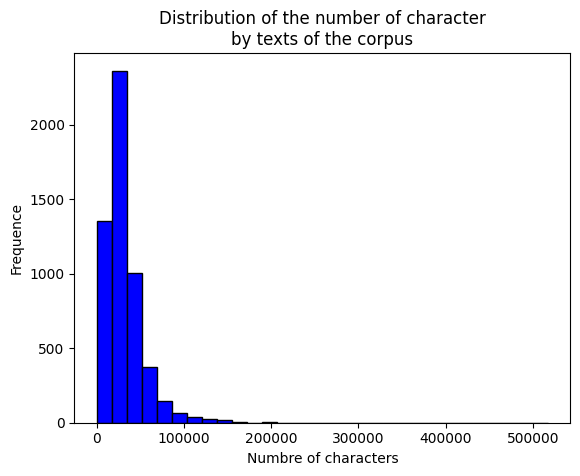

In [ ]:
# 1. Function to plot frequency histogram
def plot_char_histogram(text_list, title_text):
    text_lengths = [len(text) for text in text_list]

    plt.hist(text_lengths, color='blue', edgecolor="black", bins=30, range=[0, 517203])
    plt.xlabel('Number of characters')
    plt.ylabel('Frequency')
    plt.title(title_text)
    plt.show()

# 2. Plot histogram characters
plot_char_histogram(corpus,
                    'Distribution of the number of character\nby texts of the corpus')

### 1.b) Descriptive statistics

In [ ]:
# 1. Descriptive statistics header
print(f"\033[1mDescriptive statistics\033[0m")
print(f"------------------------------------------------")

# 2. Minimum :
min_characters = min(len(text) for text in corpus)
print(f"Minimum number of characters: {min_characters}")

# 3. Mean :
total_characters = sum(len(text) for text in corpus)
mean_characters = total_characters/len(corpus)
print(f"\nMean number of characters: {mean_characters}")

# 4. Quartiles and median :
character_lengths = [len(text) for text in corpus]
Q1_char = np.percentile(character_lengths, 25)
Median_char = np.percentile(character_lengths, 50) #Q2
Q3_char = np.percentile(character_lengths,75)

print(f"\nQ1: {Q1_char}")
print(f"\nMedian: {Median_char}")
print(f"\nQ3: {Q3_char}")

# 5. Maximum :
max_characters = max(len(text) for text in corpus)
print(f"\nMaximum number of characters: {max_characters}")

# 6. Std deviation :
std_deviation = np.std(character_lengths)
print(f"\nStandard Deviation number of characters: {std_deviation}")

Descriptive statistics
------------------------------------------------
Minimum number of characters: 3310

Mean number of characters: 31215.4145844901

Q1: 17194.5

Median: 25672.0

Q3: 38568.5

Maximum number of characters: 517203

Standard Deviation number of characters: 22570.102728387545


In [ ]:
# 8. Create a dataframe with results
df_stat_descr = pd.DataFrame({"Minimum": [min_characters],
                              "Q1": [Q1_char],
                              "Median": [Median_char],
                              "Mean": [mean_characters],
                              "Q3": [Q3_char],
                              "Maximum": [max_characters],
                              "Standard Deviation" : [std_deviation]})
df_stat_descr.index =["Character"]
df_stat_descr

,Minimum,Q1,Median,Mean,Q3,Maximum,Standard Deviation
Character,3310,17194.5,25672.0,31215.414584,38568.5,517203,22570.102728


## 2\. Word count

###2.a) Load tokenized corpus

In [ ]:
# 1.Function to loop the count of tokens in files of the directory
def count_items_in_json_file(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)
        return len(data)

### 2.b) Visualization

In [ ]:
# 2.Define function to plot histogram
def plot_tokens_histogram(json_files_directory, title_text):
    item_counts = []

    # Loop through each JSON file in the directory
    for file_name in os.listdir(json_files_directory): # We use the function defined above
        if file_name.endswith(".json"):
            file_path = os.path.join(json_files_directory, file_name)
            item_count = count_items_in_json_file(file_path)
            item_counts.append(item_count)

    plt.hist(item_counts, bins=30 , edgecolor="black", density=False, range=[0, 126057], color='orange')
    plt.xlabel('Number of Tokens')
    plt.ylabel('Frequency')
    plt.title(title_text)
    plt.show()

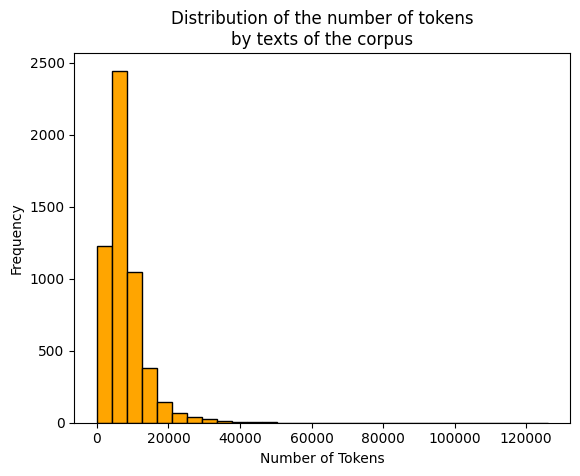

In [ ]:
# 3.Plot histogram
json_files_directory="/content/drive/MyDrive/02.Memoire/Data/01-Token_Words_json"
plot_tokens_histogram(json_files_directory,
                      'Distribution of the number of tokens\nby texts of the corpus')

### 2.c) Descriptive statistics

In [ ]:
# 1. Descriptive statistics header
print(f"\033[1mDescriptive statistics\033[0m")
print(f"------------------------------------------------")

# 2. Count total tokens
total_tok = 0
for file_name in os.listdir(json_files_directory):
    if file_name.endswith(".json"):
        file_path = os.path.join(json_files_directory,file_name)
        with open (file_path, "r", encoding="utf-8") as file :
            data = json.load(file)
            total_tok += len(data)

print(f"Total of tokens in corpus:{total_tok}\n")

# 3. Minimum
# a. Function to loop in the tokenized texts
def min_toke_json(directory):
    min_tok = float("inf")
        # loop
    for file_name in os.listdir(directory):
        if file_name.endswith(".json"):
            file_path1 = os.path.join(directory, file_name)
            tok_count = count_items_in_json_file(file_path1)

            if tok_count < min_tok:
                min_tok = tok_count
    return min_tok

# b. Compute the minimum
min_tokens = min_toke_json(json_files_directory)

# c. Print results
print(f"Minimum of tokens in corpus:{print(min_tokens)}")

# 4. Quatiles and median
# a. Function to loop in the tokenized texts
def tok_quartiles(directory):
    toks_count = []
    # Loop
    for file_name in os.listdir(directory):
        if file_name.endswith(".json"):
            file_path = os.path.join(directory, file_name)
            tok_count = count_items_in_json_file(file_path)
            toks_count.append(tok_count)
    Q1_tok = np.percentile(toks_count, 25)
    Median_tok = np.percentile(toks_count, 50)
    Q3_tok = np.percentile(toks_count, 75)

    return Q1_tok, Median_tok, Q3_tok

# b. Compute Q1, Median, Q3
Q1_tok, Median_tok, Q3_tok = tok_quartiles(json_files_directory)

# c. Print results
print(f"\nQ1 tok: {Q1_tok}")
print(f"\nMedian tok: {Median_tok}")
print(f"\nQ3 tok: {Q3_tok}")

# 5. Mean
# a. Compute results
mean_tok = total_tok/len(corpus)

# b. Print results
print(f"\nMean number of tokens: {mean_tok}")

# 6. Maximum
# a. Function to loop in the token files
def max_toke_json(directory):
    max_tok = float("-inf")
        # Loop
    for file_name in os.listdir(directory):
        if file_name.endswith(".json"):
            file_path2 = os.path.join(directory, file_name)
            tok_count = count_items_in_json_file(file_path2)

            if tok_count > max_tok:
                max_tok = tok_count
    return max_tok

# b. Compute tokens
max_tokens = max_toke_json(json_files_directory)

# c. Print results
print(f"\nMaximum number of tokens: {max_tokens}")

# 7. Standard deviation
# a. Initiate list for count
toks_counts = []

# b. Loop through the token files
for file_name in os.listdir(json_files_directory):
    if file_name.endswith(".json"):
        file_path = os.path.join(json_files_directory, file_name)
        with open(file_path, "r", encoding="utf-8") as file:
            data = json.load(file)
            tok_count = len(data)
            toks_counts.append(tok_count)

# c. Compute Std dev
std_deviation_tok = np.std(toks_counts)

# d. Print std deviation
print(f"\nStandard Deviation number of tokens: {std_deviation_tok}")

Descriptive statistics
------------------------------------------------
Total of tokens in corpus:41984672

987
Minimum of tokens in corpus:None

Q1 tok: 4380.0

Median tok: 6409.0

Q3 tok: 9554.0

Mean number of tokens: 7770.62224689987

Maximum number of tokens: 126056

Standard Deviation number of tokens: 5468.134403683522


In [ ]:
# 8. Save data in dataframe
# a. temporary dataframe
df = pd.DataFrame({"Minimum": [min_tokens],
                    "Q1": [Q1_tok],
                    "Median": [Median_tok],
                    "Mean": [mean_tok],
                    "Q3": [Q3_tok],
                    "Maximum": [max_tokens],
                    "Standard Deviation": [std_deviation_tok]})

# b. Concat to existing dataframe
df.index = ["Tokens"]

df_stat_descr = pd.concat([df_stat_descr, df], ignore_index=False)
print(df_stat_descr.to_string())

# c. Clean data
del(df)

           Minimum       Q1   Median          Mean       Q3  Maximum  Standard Deviation
Character     3310  17194.5  25672.0  31215.414584  38568.5   517203        22570.102728
Tokens         987   4380.0   6409.0   7770.622247   9554.0   126056         5468.134404


##3\. Sentences count

### 3.a) Load sentences

In [ ]:
# 1. Function to load sentences
def load_tokenized_sentences(directory):
    loaded_sentences_list = []

    for file_name in os.listdir(directory):
        if file_name.endswith(".pkl"):
            file_path = os.path.join(directory, file_name)
            with open(file_path, "rb") as file:
                loaded_tokenized_sentences = pickle.load(file)
                loaded_sentences_list.append(loaded_tokenized_sentences)

    return loaded_sentences_list

In [ ]:
# 2. Loading the corpus
save_directory = "/content/drive/MyDrive/02.Memoire/Data/02-Token_Sentences_pkl"

corpus_tokenized_sentences = load_tokenized_sentences(save_directory)

### 3.b) Visualization

In [ ]:
# 1. Function to count sentences
def count_sentences(text_list):
    sentences_counts = [len(list(text)) for text in text_list]
    return sentences_counts

# 2. Function to plot Histogram
def plot_sentence_count_hist(text_list):
    sentence_counts = count_sentences(text_list) # Call function to count sentences

    plt.hist(sentence_counts, bins=30, edgecolor="black", density=False, color="salmon", range=[0, 3298])
    plt.xlabel("Number of sentences")
    plt.ylabel("Frequency")
    plt.title('Distribution of the number of sentences\nby texts of the corpus')
    plt.show()

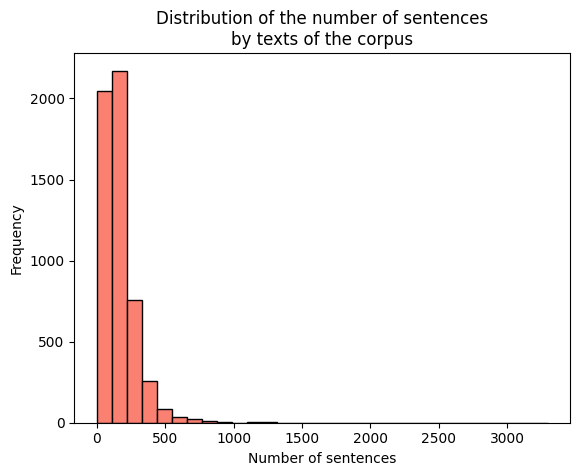

In [ ]:
# 3. Plot the histogram
plot_sentence_count_hist(corpus_tokenized_sentences)

###3.c) Descriptive statistics

In [ ]:
# 1. Descriptive statistics header
print(f"\033[1mDescriptive statistics\033[0m")
print(f"------------------------------------------------")

# 2. Minimum
def find_minimum_sentences(tokenized_texts):
    if not tokenized_texts:
        return 0  # Return 0 for an empty list

    min_sentences = min(len(sentences) for sentences in tokenized_texts)
    return min_sentences


min_sentence = find_minimum_sentences(corpus_tokenized_sentences)
print(f"Minimum of sentences in corpus:{min_sentence}\n")


# 3. Mean
total_sentence_count = sum(len(sentences) for sentences in corpus_tokenized_sentences)
print(f"Total of sentences in corpus:{total_sentence_count}\n")

mean_sentences = total_sentence_count/len(corpus_tokenized_sentences)
print(f"Mean of sentences in corpus:{mean_sentences}\n")

# 4. Quartiles and median
sentences_lengths = [len(sentences) for sentences in corpus_tokenized_sentences]
Q1_sentences = np.percentile(sentences_lengths, 25)

median_sentences = np.percentile(sentences_lengths, 50)

Q3_sentences = np.percentile(sentences_lengths, 75)

print(f"Q1 sentences: {Q1_sentences}\n")
print(f"Median sentences: {median_sentences}\n")
print(f"Q3 sentences: {Q3_sentences}\n")


# 5. Maximum
def find_maximum_sentences(tokenized_texts):
    if not tokenized_texts:
        return 0  # Return 0 for an empty list

    max_sentences = max(len(sentences) for sentences in tokenized_texts)
    return max_sentences

max_sentence = find_maximum_sentences(corpus_tokenized_sentences)

print(f"Maximum of sentences in corpus:{max_sentence}\n")

# 6. Standard deviation
std_deviation_sentences = np.std(sentences_lengths)

print(f"Standard deviations of sentences in corpus:{std_deviation_sentences}\n")


Descriptive statistics
------------------------------------------------
Minimum of sentences in corpus:5

Total of sentences in corpus:887661

Mean of sentences in corpus:164.2903942254303

Q1 sentences: 86.0

Median sentences: 133.0

Q3 sentences: 207.0

Maximum of sentences in corpus:2687

Standard deviations of sentences in corpus:126.60553385004467



In [ ]:
df = pd.DataFrame({"Minimum": [min_sentence],
                    "Q1": [Q1_sentences],
                    "Median": [median_sentences],
                    "Mean": [mean_sentences],
                    "Q3": [Q3_sentences],
                    "Maximum": [max_sentence],
                    "Standard Deviation": [std_deviation_sentences]})
df.index = ["Sentences"]
df_stat_descr = pd.concat([df_stat_descr, df], ignore_index=False)
print(df_stat_descr.to_string())
del(df)


           Minimum       Q1   Median          Mean       Q3  Maximum  Standard Deviation
Character     3310  17194.5  25672.0  31215.414584  38568.5   517203        22570.102728
Tokens         987   4380.0   6409.0   7770.622247   9554.0   126056         5468.134404
Sentences        5     86.0    133.0    164.290394    207.0     2687          126.605534


## 4\. Semantic exploration

### 4.a) Load tokens

In [ ]:
# 1. Function to load tokens
def load_tokenized_words(directory):
    loaded_words_list = []

    for file_name in os.listdir(directory):
        if file_name.endswith(".pkl"):
            file_path = os.path.join(directory, file_name)
            with open(file_path, "rb") as file:
                loaded_tokenized_texts = pickle.load(file)
                loaded_words_list.append(loaded_tokenized_texts)

    return loaded_words_list

In [ ]:
# 2. Remount the drive and redeclare path
from google.colab import drive
drive.mount('/content/drive')
token_directory = "/content/drive/MyDrive/02.Memoire/Data/03-Token_Words_pkl"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 3. Load tokenized corpus
tokenized_texts = load_tokenized_words(token_directory)

### 4.b) Plot token repartition - No cleaning

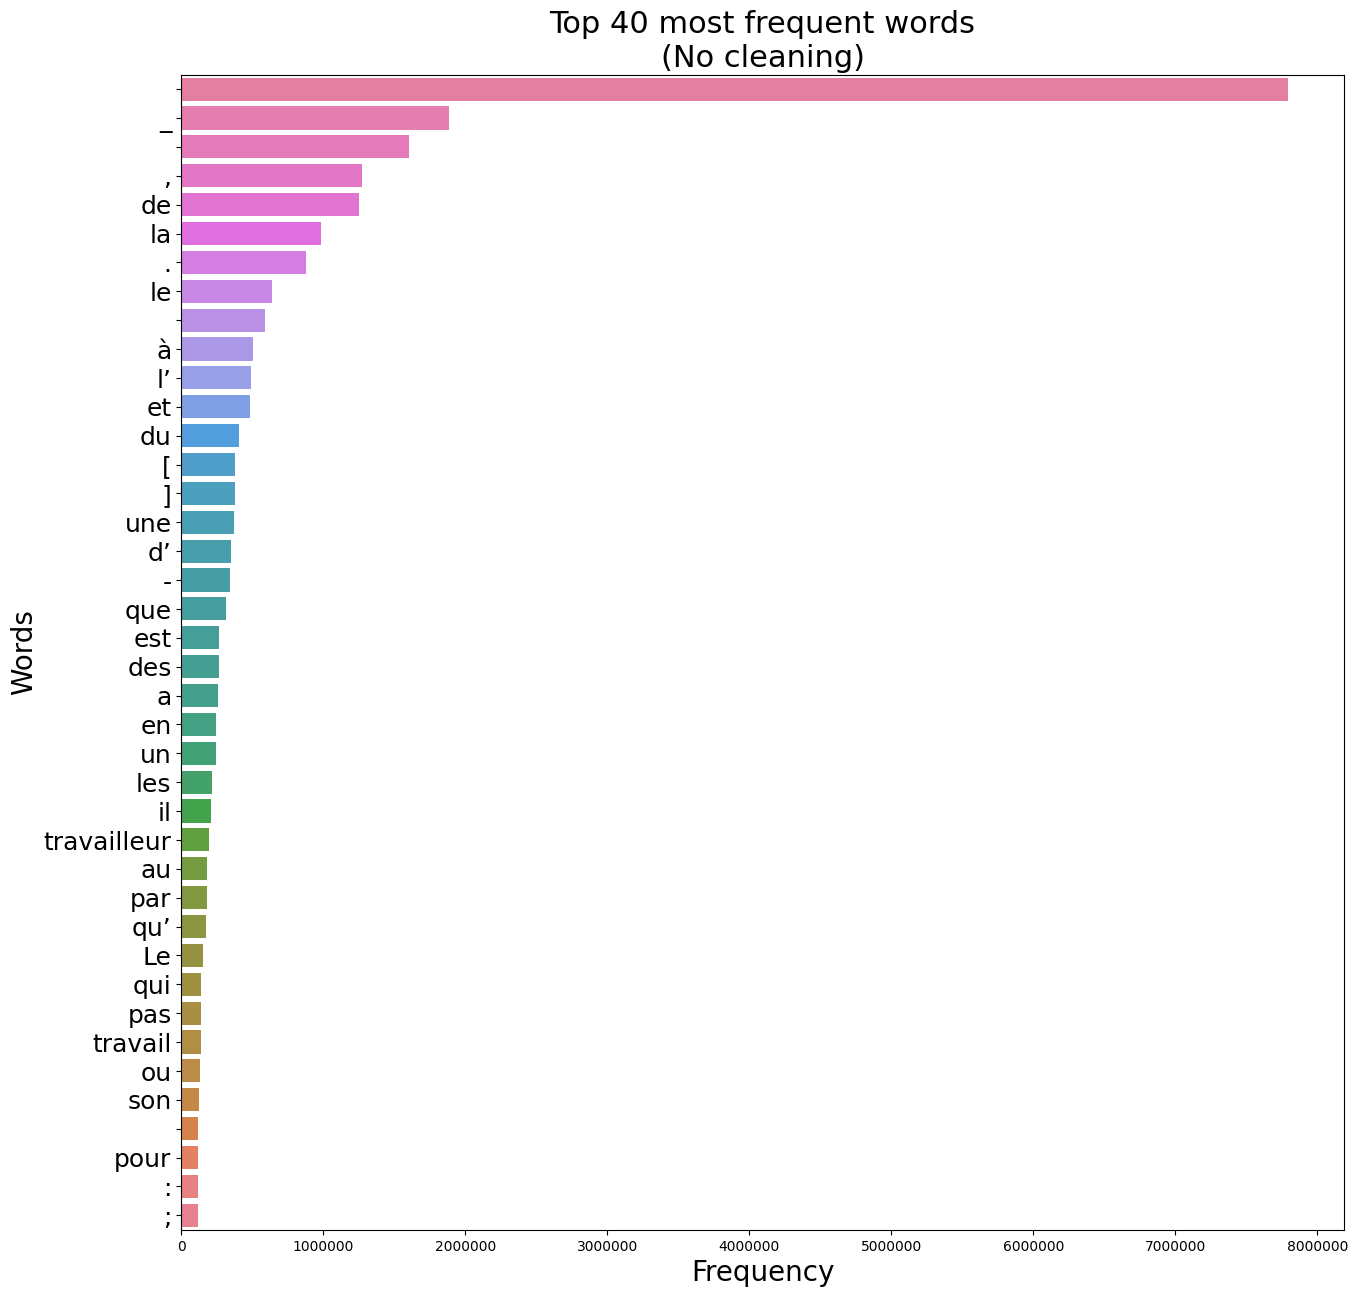

In [ ]:
all_tokens = [token for tokens in tokenized_texts for token in tokens]

counter = Counter(all_tokens)
most = counter.most_common()

x, y = [], []
for word, count in most[:40]:
    x.append(word)
    y.append(count)

cols = seaborn.color_palette("husl", len(x))

plt.figure(figsize=(15, 15))
plt.ticklabel_format(style='plain')
bp1 = seaborn.barplot(x=y, y=x, hue=y, palette=cols, legend= False)
bp1.set_title('Top 40 most frequent words''\n''(No cleaning)', fontsize=22)
bp1.set_xlabel("Frequency", fontsize = 20)
bp1.set_ylabel("Words", fontsize = 20)
bp1.tick_params(axis='y', labelsize=18)

### 4.c) First cleaning
* Lower case all tokens
* list of nltk stop words in french
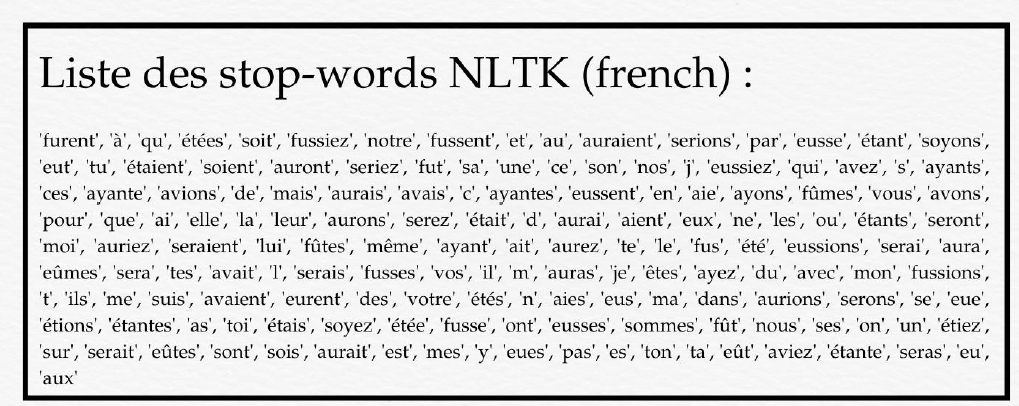

In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

/tmp/ipykernel_16777/355509539.py:19: UserWarning: The palette list has more values (40) than needed (16), which may not be intended.
  seaborn.barplot(x=y1, y=x1, hue=y1, palette=cols, legend=False)


<Axes: >

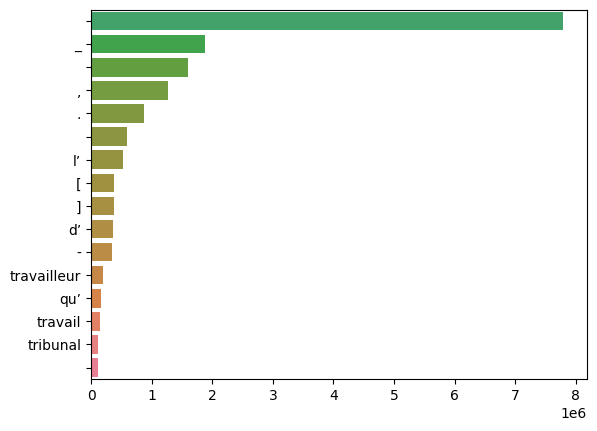

In [ ]:
# 1. Lower case
all_tokens_l = [token.lower() for token in all_tokens]

counter1 = Counter(all_tokens_l)
most1 = counter1.most_common()

# 2. Stop words
stp_words = set(stopwords.words('french'))
personnal_stopwords = ["–", "a", "l", "a.", "«", "»", "c.", "d'", "l'", "qu'", "n'","s'"]
stp_words = stp_words.union(personnal_stopwords)


x1, y1 = [], []
for word, count in most1[:40]:
    if (word not in stp_words):
        x1.append(word)
        y1.append(count)

seaborn.barplot(x=y1, y=x1, hue=y1, palette=cols, legend=False)

### 4.d) Second cleaning
* remove case number AZ-******
* remove spaces in tokens
* remove other case numbers
* remove digits
* remove \n
* remove booleans
* remove blanks
* remove '
* remove stop-words
* remove punctuation


In [ ]:
# 1. Regex patterns to clean data
pattern = re.compile(r'^az-\d+$')
pattern1 = re.compile(r'\s')


all_tokens_filtered = [token for token in all_tokens_l if not pattern.match(token)]
all_tokens_filtered = [token for token in all_tokens_filtered if not re.search(r'\d', token)]
all_tokens_filtered = [token.replace("\n", "") for token in all_tokens_filtered]
all_tokens_filtered = [token for token in all_tokens_filtered if bool(token)]
all_tokens_filtered = [token for token in all_tokens_filtered if not pattern1.match(token)]
all_tokens_filtered = [token.replace("'", "") for token in all_tokens_filtered]
all_tokens_filtered = [token for token in all_tokens_filtered if token not in stp_words]
all_tokens_filtered = [token for token in all_tokens_filtered if not all(char in string.punctuation for char in token)]

In [ ]:
# 2. Count tokens to initiate ratio
tokens_count = Counter(all_tokens_filtered)
most2 = tokens_count.most_common()

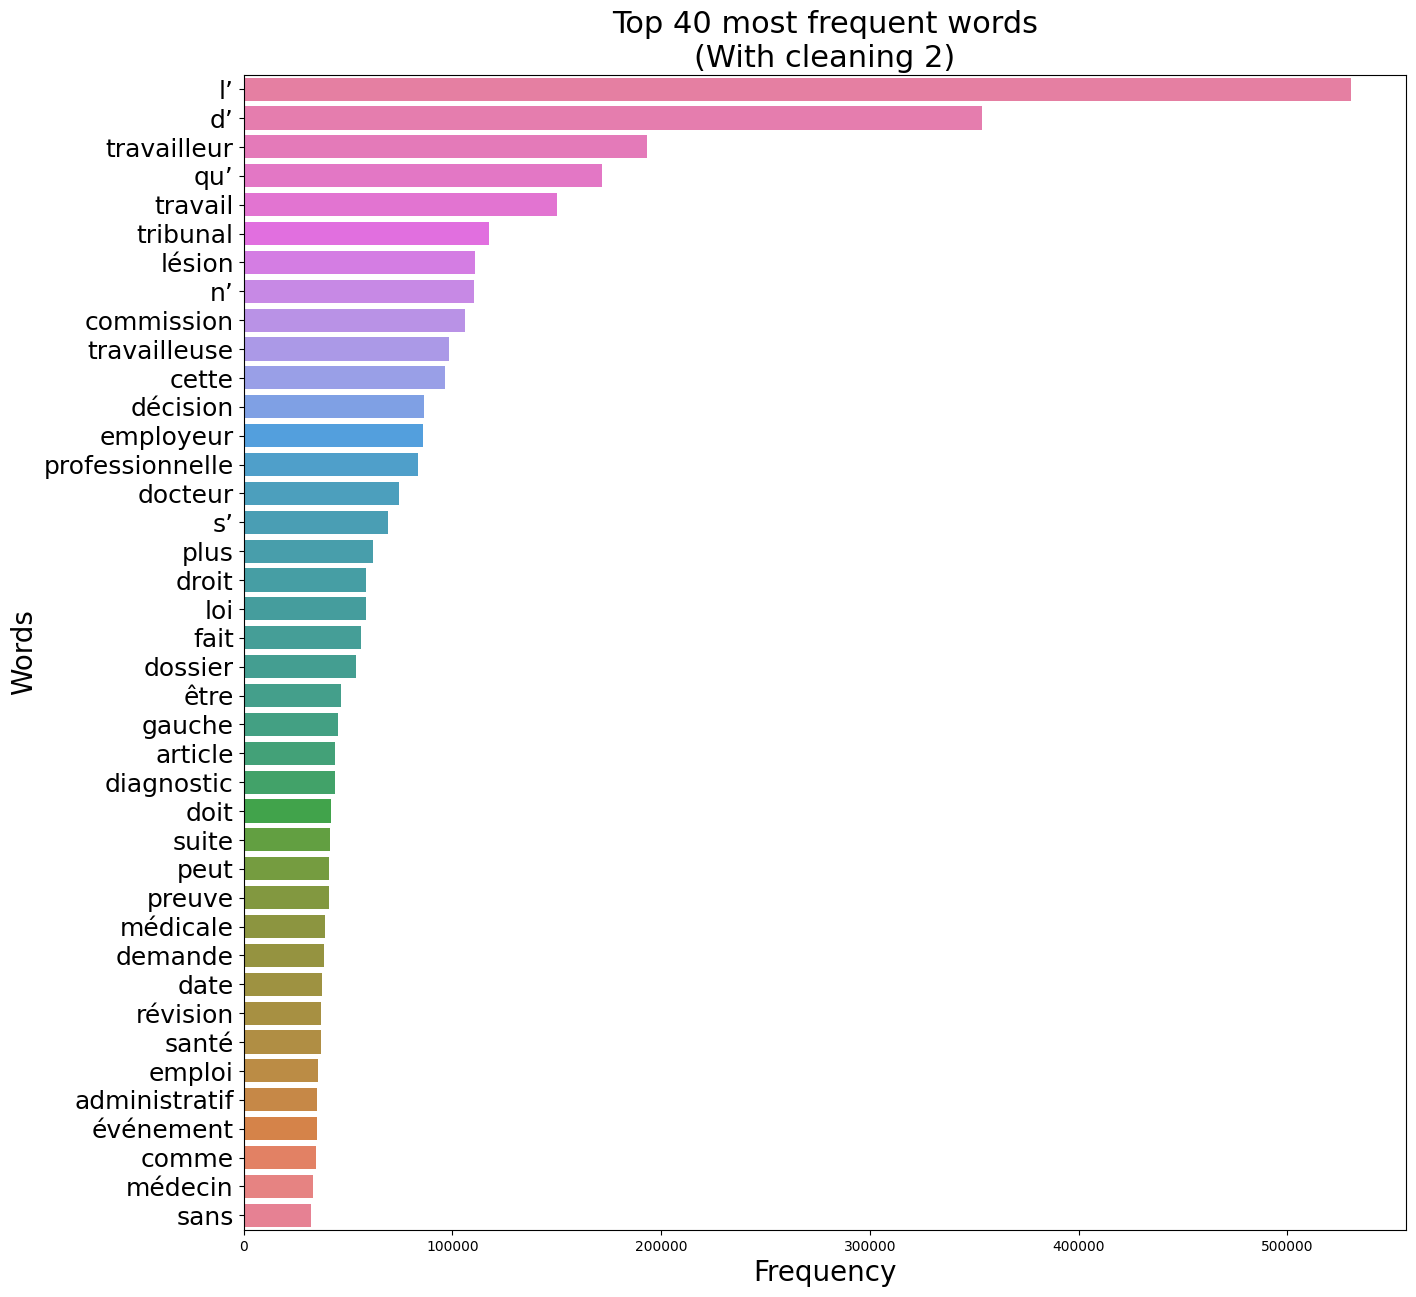

In [ ]:
# 3. Plot top 40 tokens after cleaning
x2, y2 = [], []
for word, count in most2[:40]:
        x2.append(word)
        y2.append(count)

#4.e) Bar plot of the 40 most frequent tokens
cols = seaborn.color_palette("husl", len(x2))

plt.figure(figsize=(15, 15))
bp2 = seaborn.barplot(x=y2, y=x2, hue=y2, palette=cols, legend=False)
bp2.set_title('Top 40 most frequent words''\n''(With cleaning 2)', fontsize=22)
bp2.set_xlabel("Frequency", fontsize = 20)
bp2.set_ylabel("Words", fontsize = 20)
bp2.tick_params(axis='y', labelsize=18)

In [ ]:
# 4. Dataframe of top and lowest tokens
df_tok = pd.DataFrame(list(tokens_count.items()), columns=['Token', 'Count'])
df_tok = df_tok.sort_values(by='Count', ascending=False).reset_index(drop=True)
print(df_tok)

                  Token   Count
0                    l’  530378
1                    d’  353859
2           travailleur  193494
3                   qu’  171584
4               travail  150043
...                 ...     ...
84342           gélifié       1
84343           backhoe       1
84344          furukawa       1
84345           scories       1
84346  ipsilatéralement       1

[84347 rows x 2 columns]


### 4.e) N-gram analytics
The n-grams are group of words. For instance `the legal procedure` or `none of the less` or `no matter`. This analysis is interesting because it allows us to get some details that could be left over by only analyzing single tokens.

In [ ]:
def plot_top_ngrams_barchart(tokens, title= "Top 40 ngrams", n=2):
    texts = tokens
    def top_ngram(texts, n=None):
        vec = CountVectorizer(ngram_range=(n, n)).fit(texts)
        bag_o_words = vec.transform(texts)
        sum_words = bag_o_words.sum(axis=0)
        words_freq = [(word, sum_words[0, idx])
                        for word, idx in vec.vocabulary_.items()]
        words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
        return words_freq[:40]

    top_n_bigrams = top_ngram(tokens, n)[:40]
    x3, y3 = map(list, zip(*top_n_bigrams))
    plt.figure(figsize=(15, 15))
    bp3 = seaborn.barplot(x=y3, y=x3, hue=y3, palette=cols, legend=False)
    bp3.set_title(title, fontsize=22)
    bp3.set_xlabel("Frequency", fontsize = 20)
    bp3.set_ylabel("Trigrams", fontsize = 20)
    bp3.tick_params(axis='y', labelsize=18)

/tmp/ipykernel_16777/305239840.py:15: UserWarning: The palette list has more values (40) than needed (30), which may not be intended.
  bp3 = seaborn.barplot(x=y3, y=x3, hue=y3, palette=cols, legend=False)


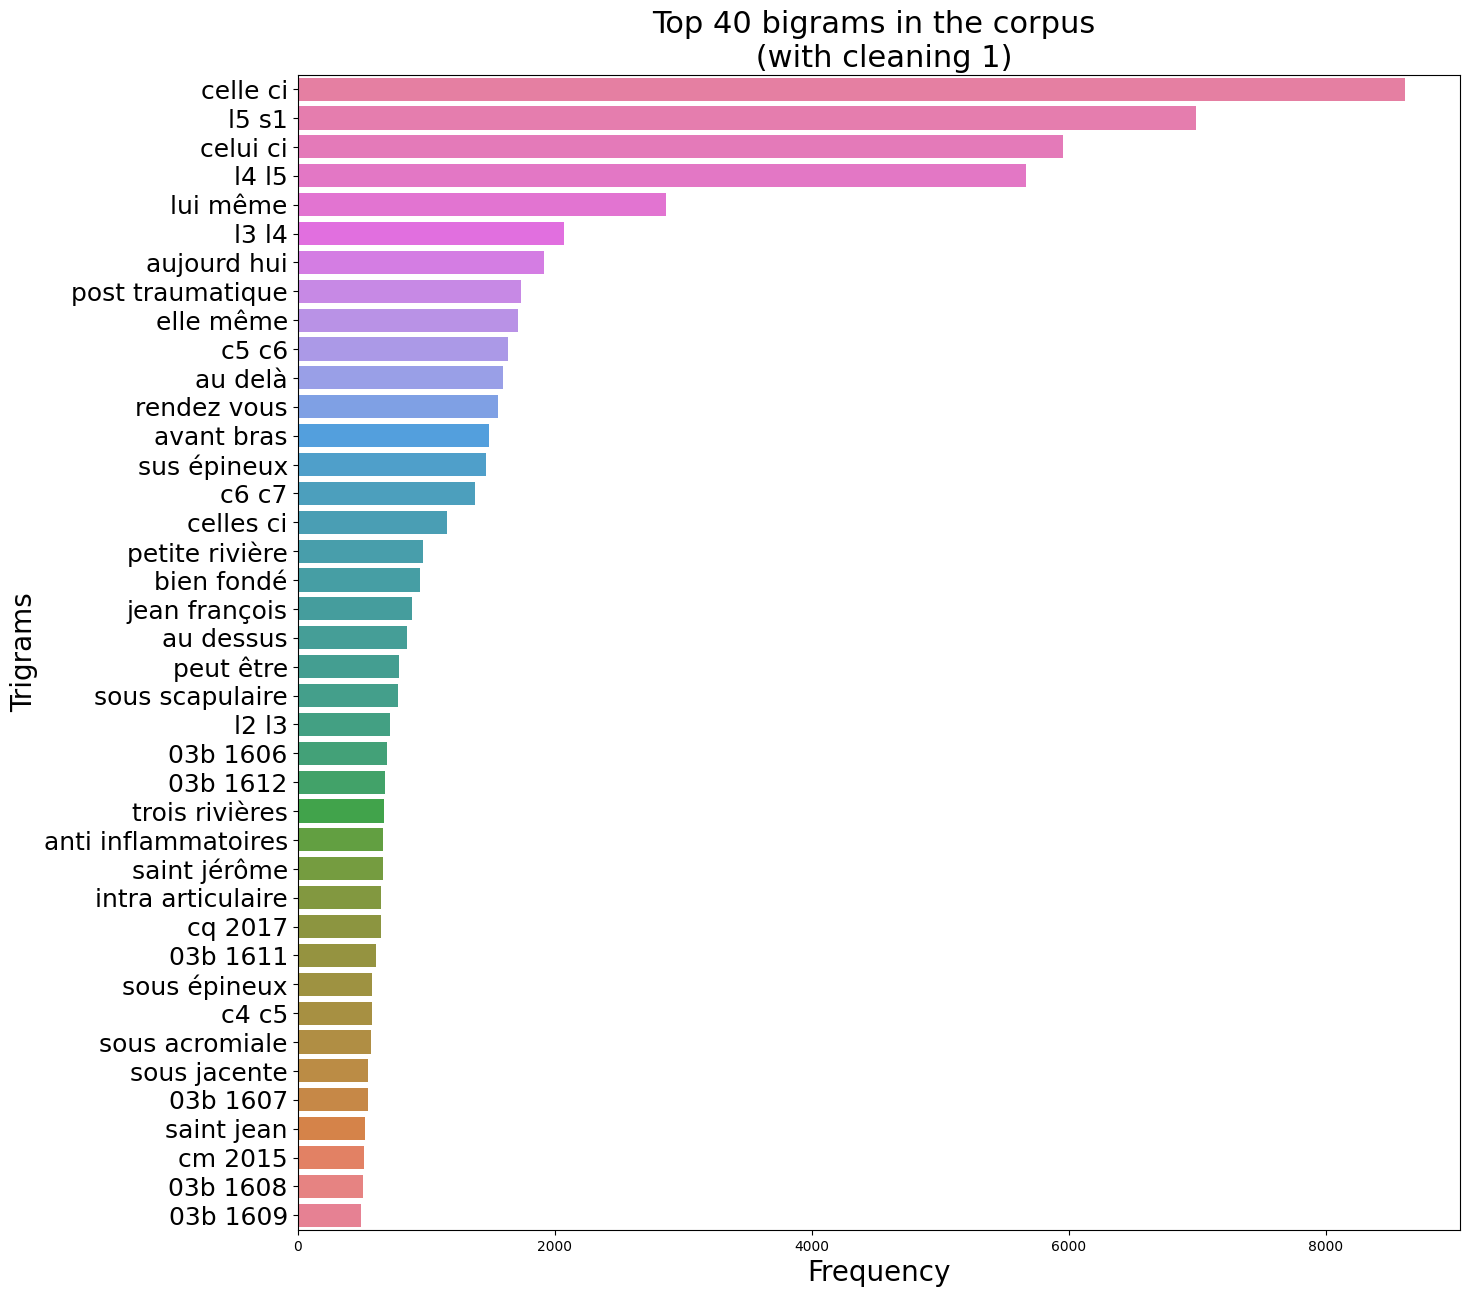

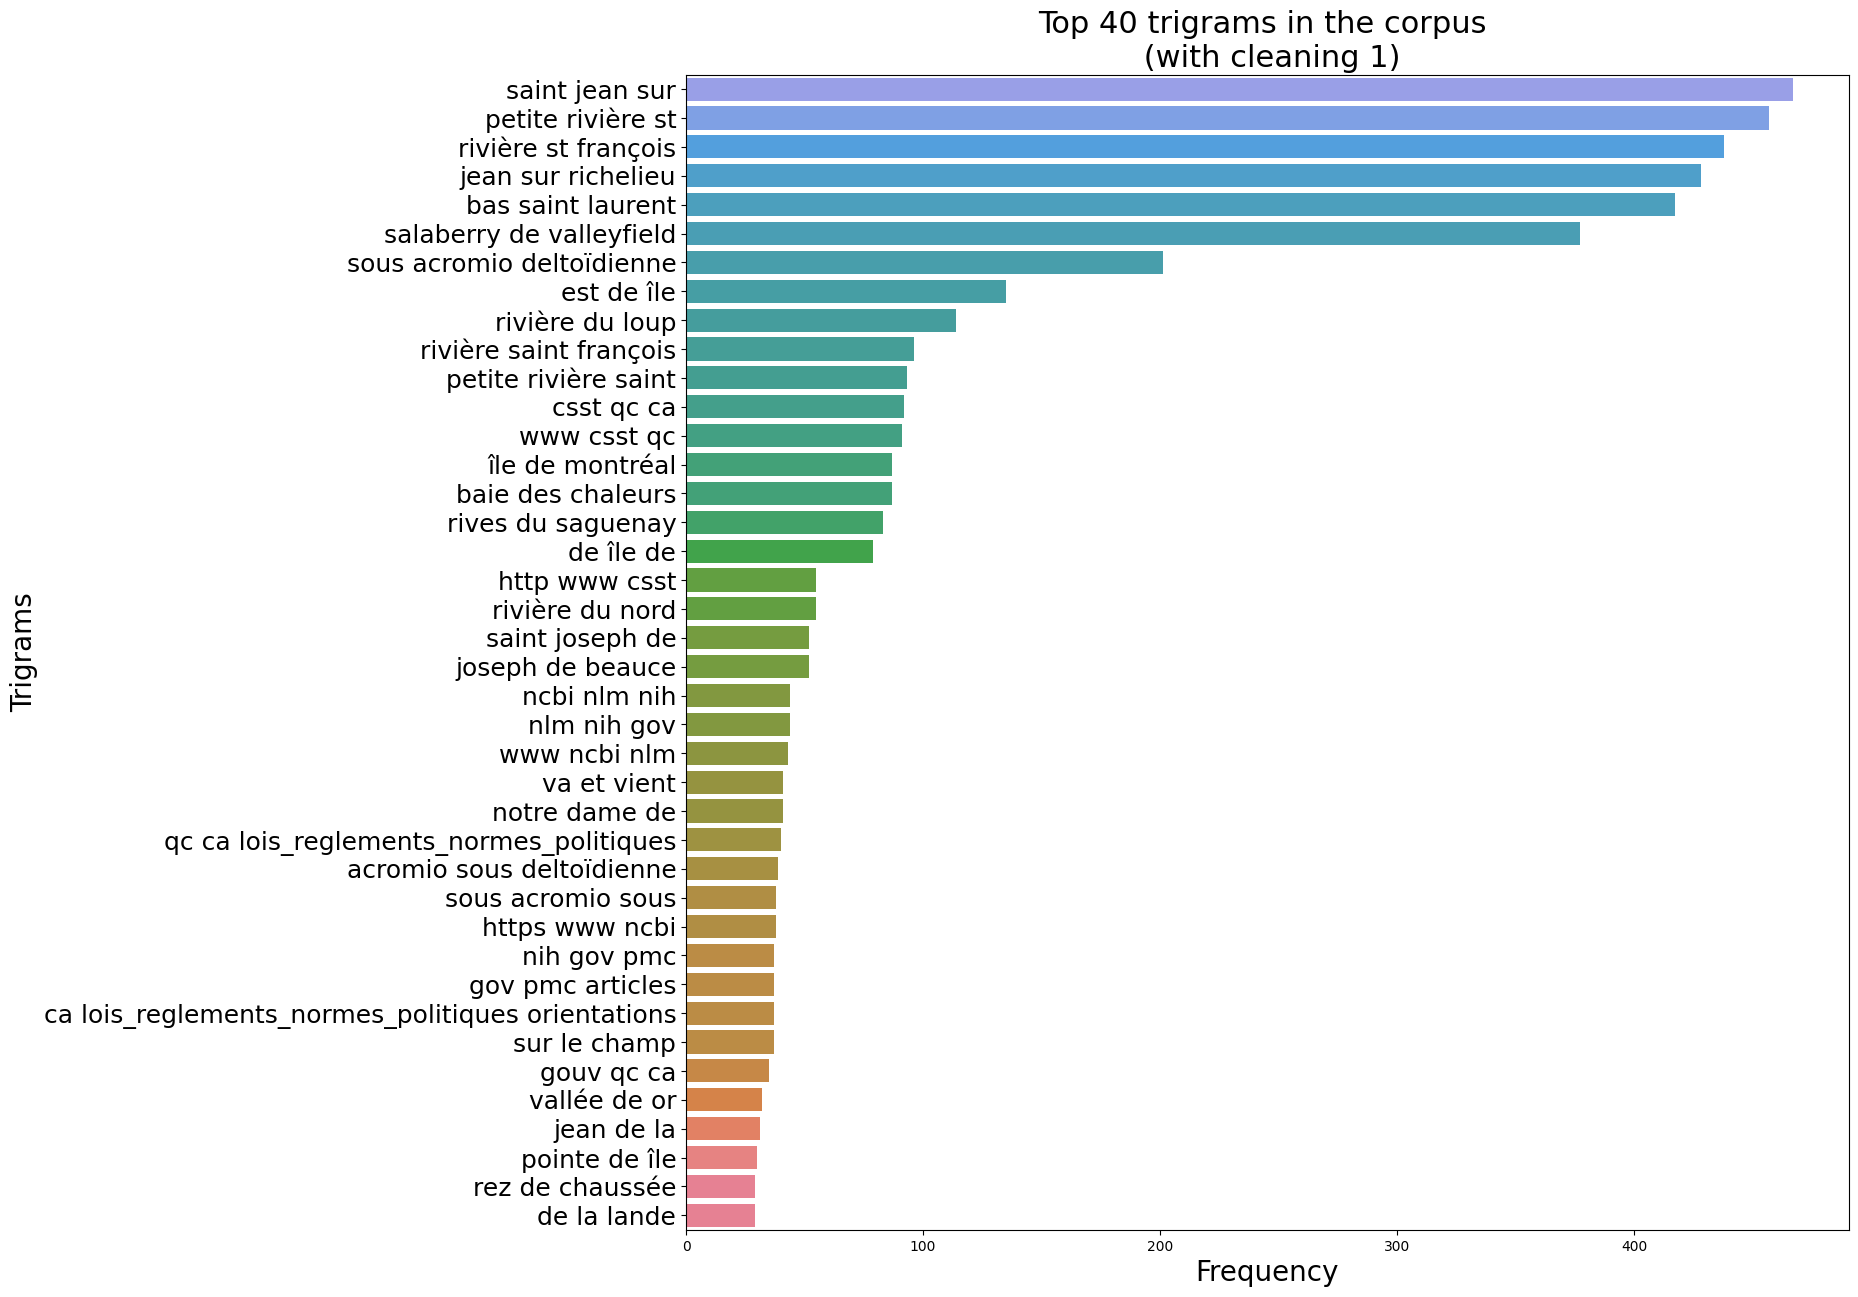

In [ ]:
plot_top_ngrams_barchart(all_tokens_l,
                         n=2,
                         title="Top 40 bigrams in the corpus \n (with cleaning 1)")

plot_top_ngrams_barchart(all_tokens_l,
                         n=3,
                         title="Top 40 trigrams in the corpus \n (with cleaning 1)")

/tmp/ipykernel_16777/305239840.py:15: UserWarning: The palette list has more values (40) than needed (35), which may not be intended.
  bp3 = seaborn.barplot(x=y3, y=x3, hue=y3, palette=cols, legend=False)
/tmp/ipykernel_16777/305239840.py:15: UserWarning: The palette list has more values (40) than needed (32), which may not be intended.
  bp3 = seaborn.barplot(x=y3, y=x3, hue=y3, palette=cols, legend=False)


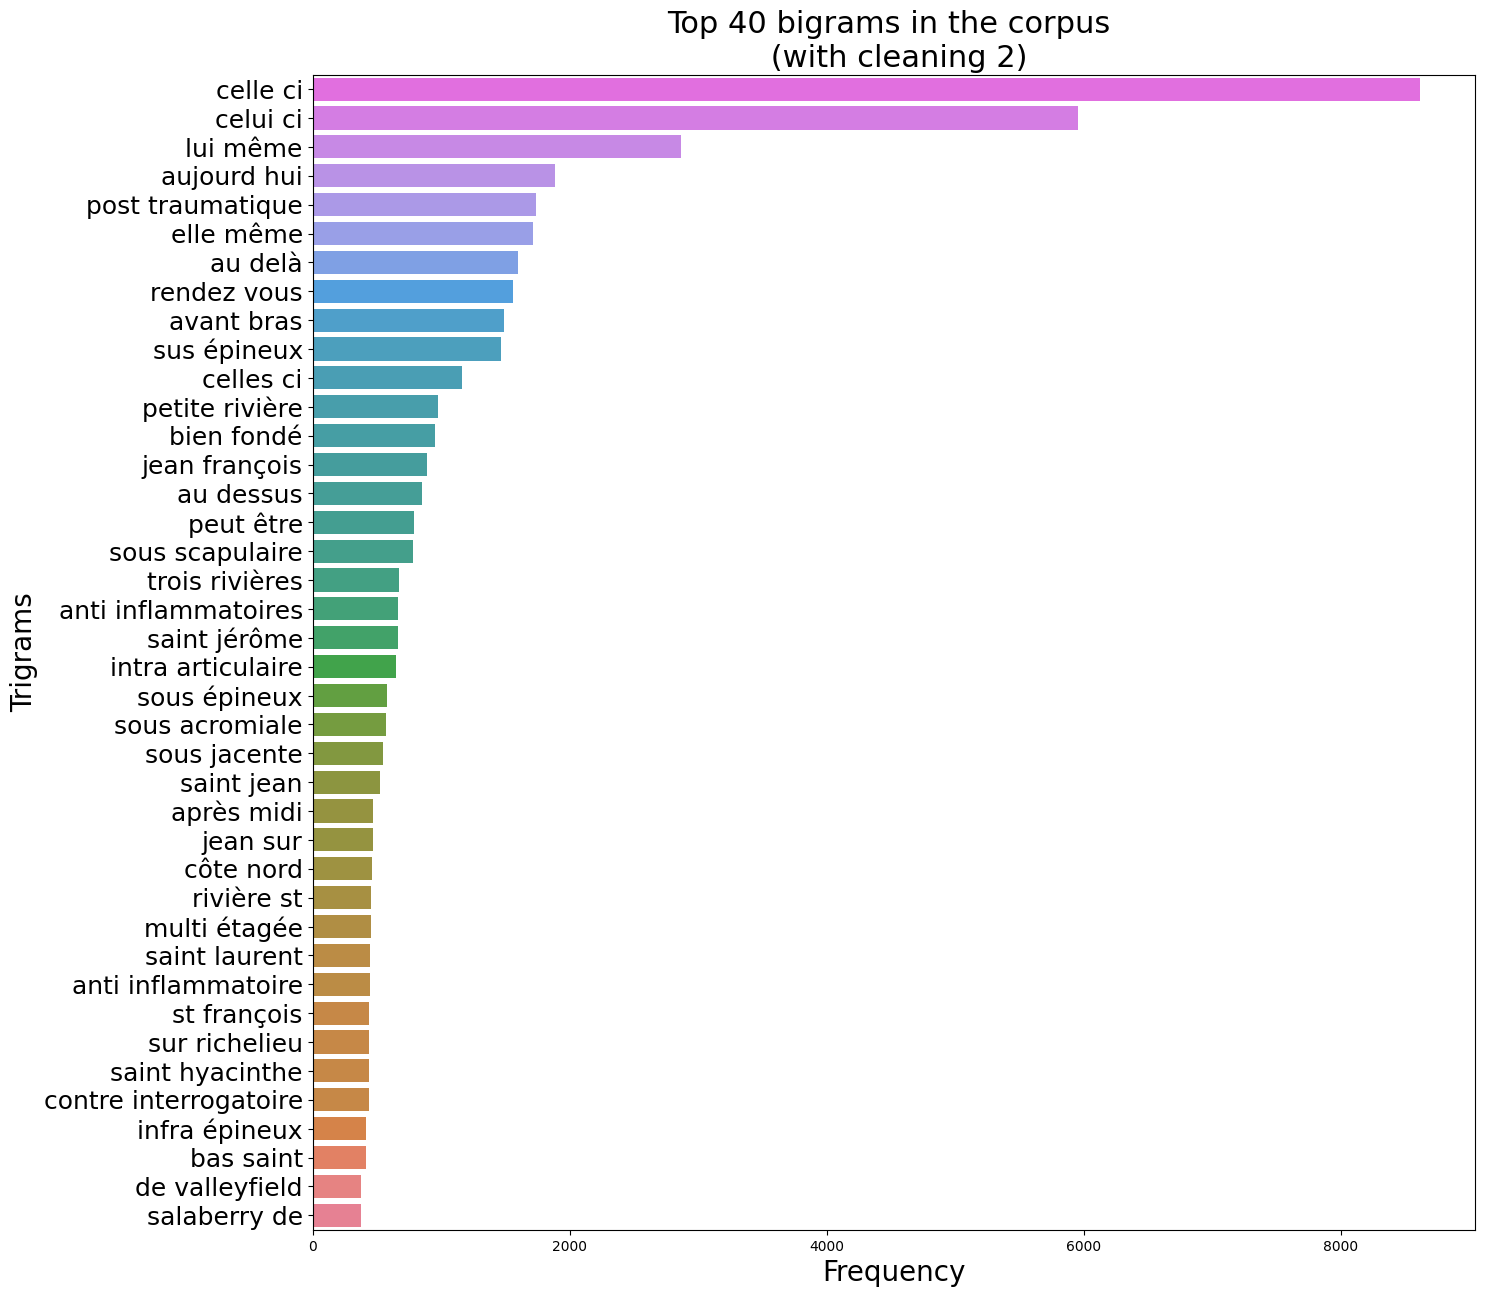

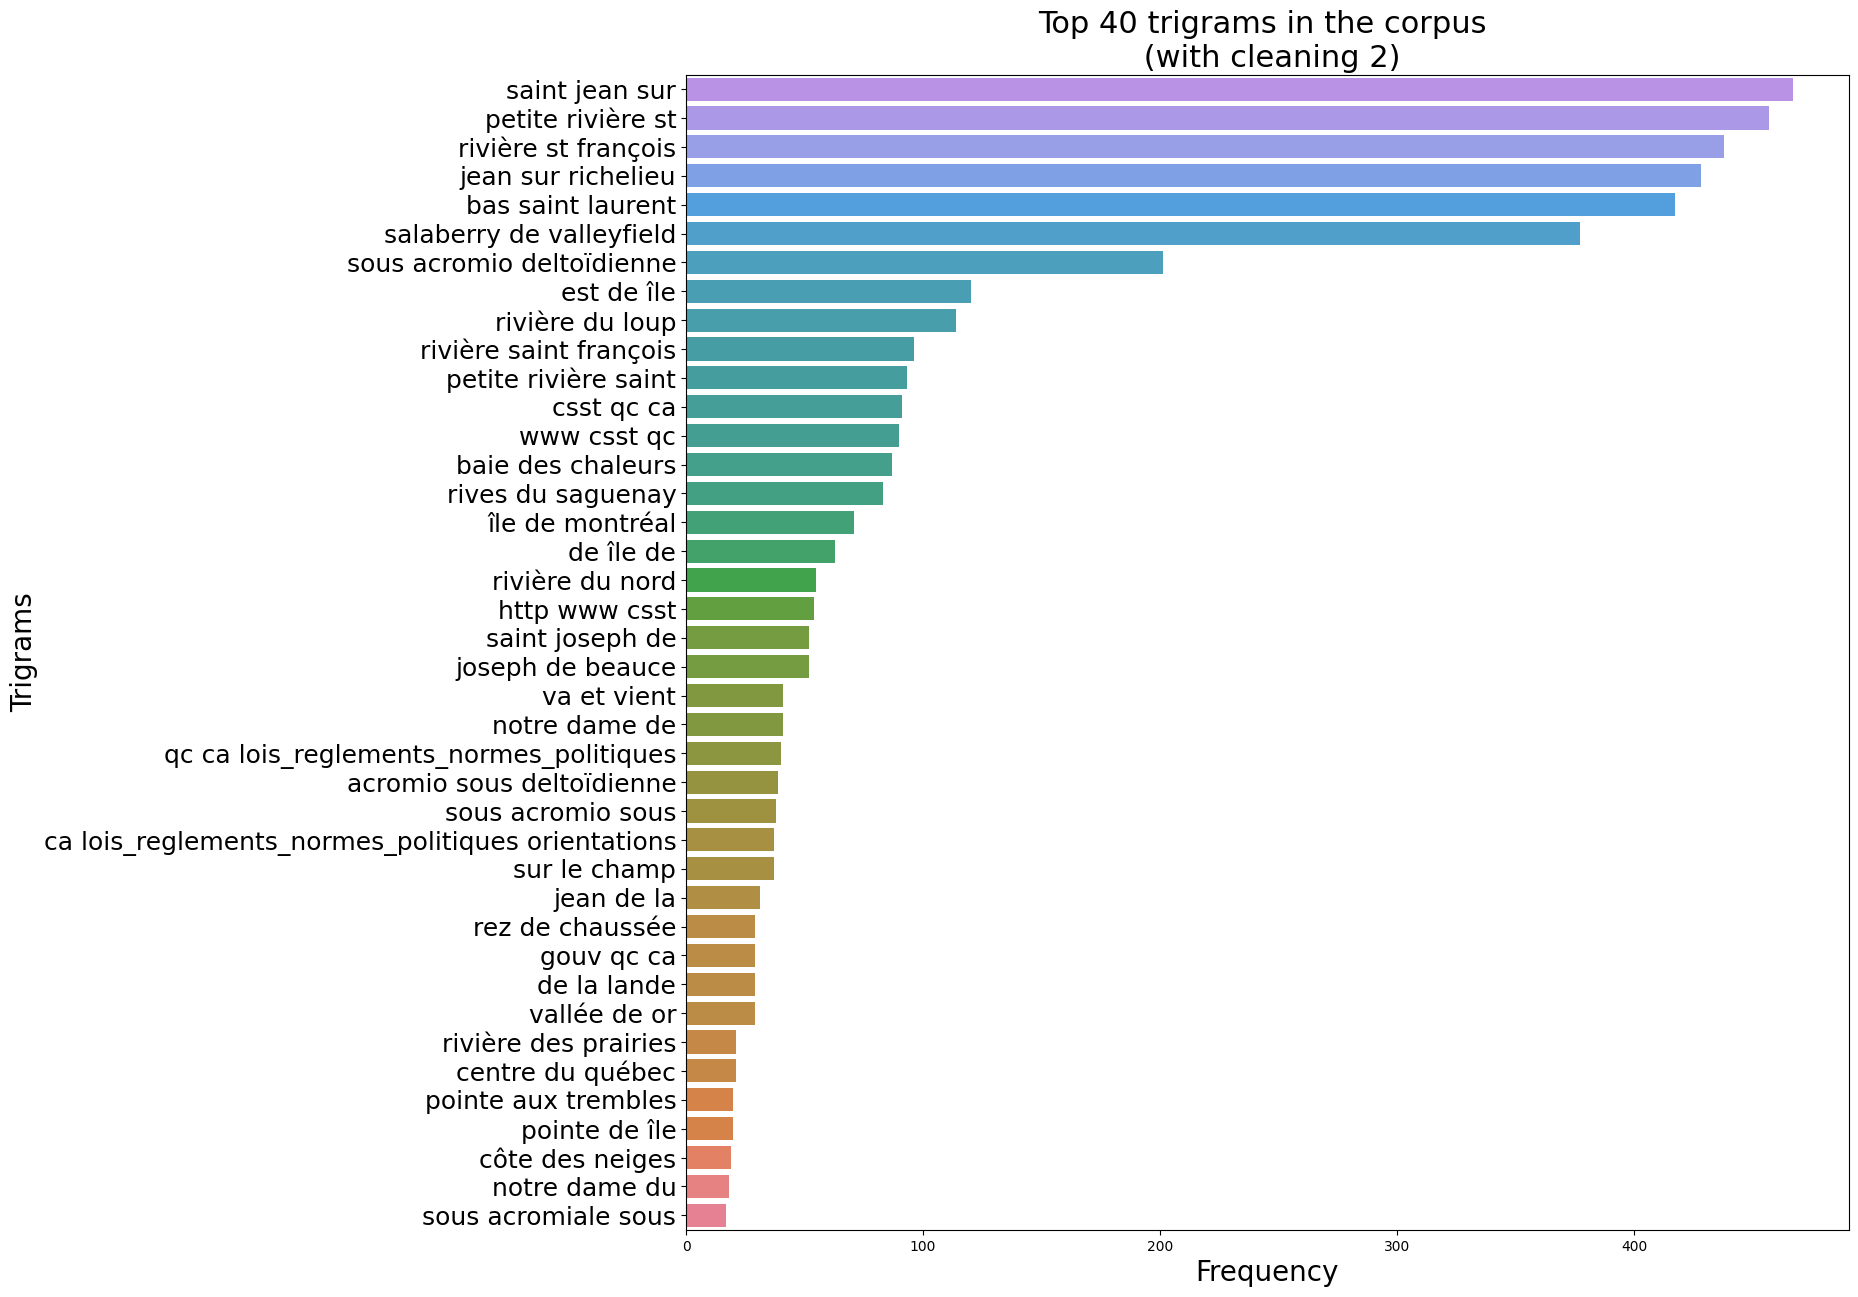

In [ ]:
plot_top_ngrams_barchart(all_tokens_filtered,
                         n=2,
                         title="Top 40 bigrams in the corpus \n (with cleaning 2)")
plot_top_ngrams_barchart(all_tokens_filtered,
                         n=3,
                         title="Top 40 trigrams in the corpus \n (with cleaning 2)")